# Загрузка библиотек

In [1]:
import time
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [2]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

Используемое устройство: cuda


# Фиксация случайности (seed) и выбор устройства

In [4]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Трансформации данных: аугментация и нормализация

In [5]:
train_transform = transforms.Compose([
  transforms.RandomCrop(32, padding=4),
  transforms.RandomHorizontalFlip(),
  transforms.ToTensor(),
  transforms.Normalize(mean, std),
])

test_transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(mean, std),
])

# Загрузка датасета и создание загрузчиков

In [6]:
train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)

Files already downloaded and verified


C:\Users\wizze\anaconda3\envs\rl_pytorch\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [7]:
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=True, transform=test_transform
)

Files already downloaded and verified


In [8]:
BATCH_SIZE = 128

In [9]:
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2
)

In [10]:
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)

# Проверка размерностей и демонстрация изображений

=== Размерности данных ===
Количество тренировочных примеров   : 50000
Количество тестовых примеров        : 10000
Форма одного изображения (C, H, W)  : (3, 32, 32)
Форма батча изображений             : (128, 3, 32, 32)
Форма меток в батче                 : (128,)
Классы                              : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']



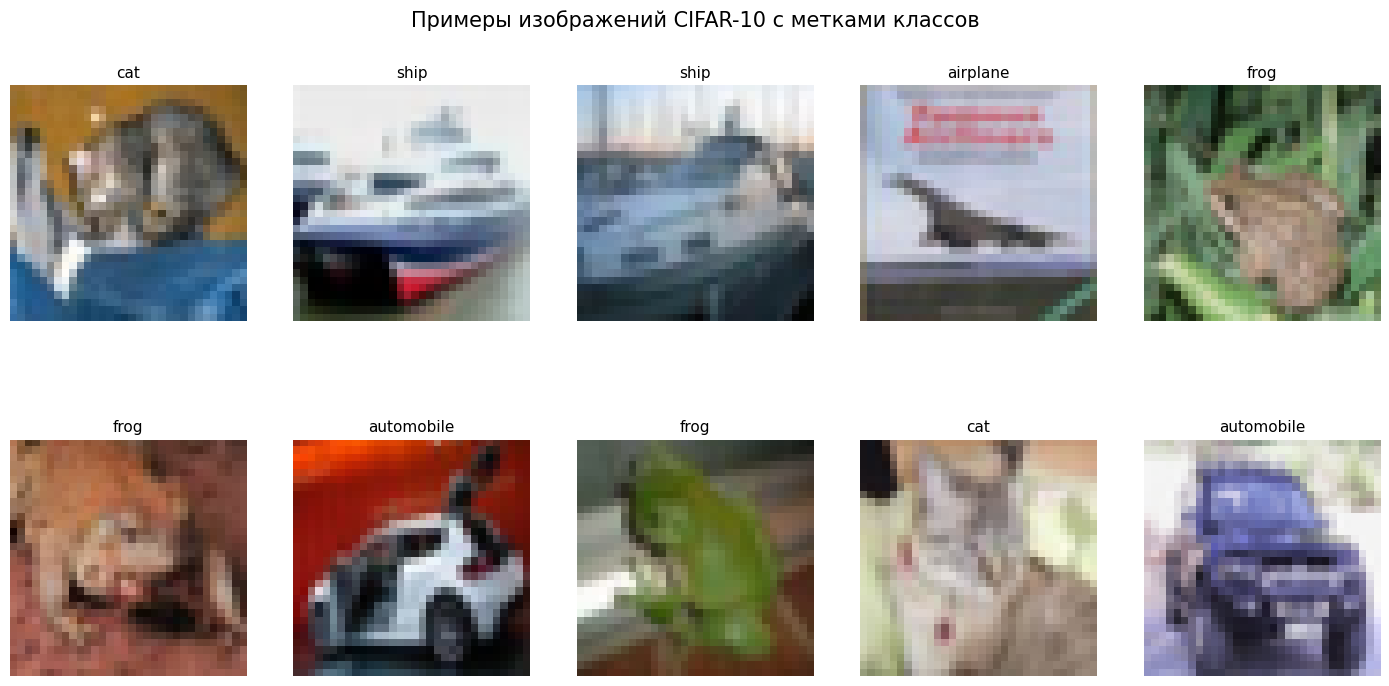

In [11]:
images, labels = next(iter(test_loader))

print("=== Размерности данных ===")
print(f"{'Количество тренировочных примеров':<36}: {len(train_dataset)}")
print(f"{'Количество тестовых примеров':<36}: {len(test_dataset)}")
print(f"{'Форма одного изображения (C, H, W)':<36}: {tuple(images[0].shape)}")
print(f"{'Форма батча изображений':<36}: {tuple(images.shape)}")
print(f"{'Форма меток в батче':<36}: {tuple(labels.shape)}")
print(f"{'Классы':<36}: {train_dataset.classes}")
print()

def denormalize(tensor):
    img = tensor.clone()
    for t, m, s in zip(img, mean, std):
        t.mul_(s).add_(m)
    return torch.clamp(img, 0, 1)

fig, axes = plt.subplots(2, 5, figsize=(14, 7))
fig.suptitle("Примеры изображений CIFAR-10 с метками классов", fontsize=15)

for ax, img, lbl in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(denormalize(img).permute(1, 2, 0).numpy())
    ax.set_title(train_dataset.classes[lbl.item()], fontsize=11, pad=6)
    ax.axis("off")

fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.subplots_adjust(hspace=0.45, wspace=0.2)
plt.show()

# Архитектура сверточной нейронной сети (класс MyCNN)

In [12]:
class MyCNN(nn.Module):
    """Собственная архитектура: 3 свёрточных блока + global average pooling + лёгкий классификатор."""
    def __init__(self, num_classes=10):
        super().__init__()
        # Блок 1: 3×32×32 -> 64×16×16
        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Блок 2: 64×16×16 -> 128×8×8
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Блок 3: 128×8×8 -> 256×4×4
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
        )
        # «Голова»: GAP + dropout + один линейный слой
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.classifier(x)
        return x

# Создание модели и подсчёт обучаемых параметров

In [13]:
model = MyCNN().to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters())
print(f"\nВсего обучаемых параметров: {total_params:,}")

dummy = torch.zeros(1, 3, 32, 32, device=device)
with torch.no_grad():
    out = model(dummy)
print("Форма выхода для одного изображения:", tuple(out.shape))

MyCNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(128, 

# Функция потерь, оптимизатор и гиперпараметры обучения

In [14]:
EPOCHS = 30
LR = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(model.parameters(), lr=LR,
                      momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# Вспомогательная функция оценки качества

In [15]:
def evaluate(loader):
    """Возвращает (потеря, точность) на заданной выборке в режиме eval."""
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss_sum += criterion(outputs, labels).item() * inputs.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

# Обучение сети

In [16]:
history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(EPOCHS):
    start = time.time()
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total
    test_loss, test_acc = evaluate(test_loader)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["train_acc"].append(train_acc)
    history["test_acc"].append(test_acc)

    print(f"Эпоха {epoch+1:2d}/{EPOCHS} | "
          f"train loss: {train_loss:.4f} | train acc: {train_acc*100:5.2f}% | "
          f"test acc: {test_acc*100:5.2f}% | {time.time()-start:.1f} с")

torch.save(model.state_dict(), "mycnn_cifar10.pth")
print("\nВеса сохранены в mycnn_cifar10.pth")

Эпоха  1/30 | train loss: 1.4550 | train acc: 46.35% | test acc: 44.92% | 17.8 с
Эпоха  2/30 | train loss: 0.9847 | train acc: 64.88% | test acc: 65.02% | 17.9 с
Эпоха  3/30 | train loss: 0.7980 | train acc: 72.22% | test acc: 56.33% | 17.8 с
Эпоха  4/30 | train loss: 0.6956 | train acc: 75.93% | test acc: 70.40% | 18.6 с
Эпоха  5/30 | train loss: 0.6356 | train acc: 78.17% | test acc: 73.12% | 18.1 с
Эпоха  6/30 | train loss: 0.5889 | train acc: 80.00% | test acc: 76.35% | 17.7 с
Эпоха  7/30 | train loss: 0.5522 | train acc: 81.17% | test acc: 70.53% | 17.9 с
Эпоха  8/30 | train loss: 0.5261 | train acc: 82.12% | test acc: 72.25% | 17.9 с
Эпоха  9/30 | train loss: 0.4978 | train acc: 83.07% | test acc: 73.34% | 17.8 с
Эпоха 10/30 | train loss: 0.4727 | train acc: 83.99% | test acc: 79.77% | 17.9 с
Эпоха 11/30 | train loss: 0.4516 | train acc: 84.48% | test acc: 78.19% | 17.9 с
Эпоха 12/30 | train loss: 0.4315 | train acc: 85.33% | test acc: 81.13% | 18.0 с
Эпоха 13/30 | train loss: 0.

# Итоговая оценка качества на тестовом наборе

In [17]:
test_loss, test_acc = evaluate(test_loader)
print("=== Итоговая оценка качества ===")
print(f"Ошибка классификации на тестовом наборе: {test_loss:.4f}")
print(f"Точность на тестовом наборе: {test_acc * 100:.2f}%")

=== Итоговая оценка качества ===
Ошибка классификации на тестовом наборе: 0.2614
Точность на тестовом наборе: 91.79%


# График изменения ошибки в процессе обучения

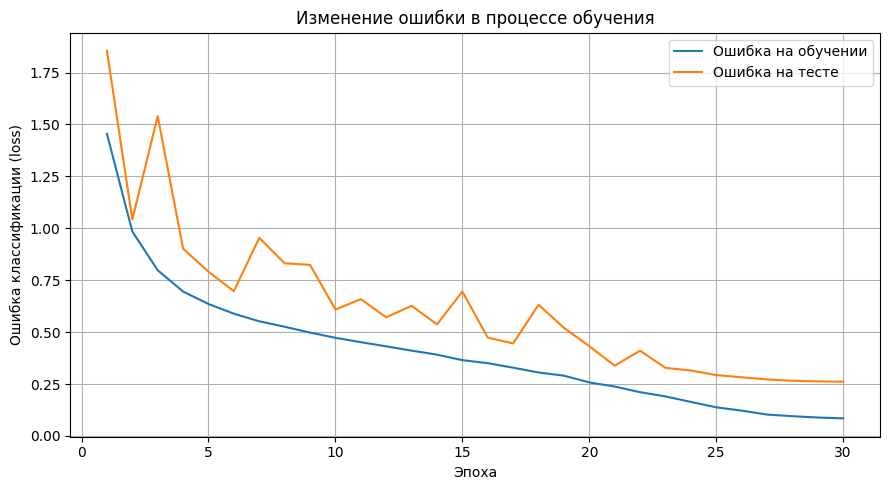

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS+1), history["train_loss"], label="Ошибка на обучении")
plt.plot(range(1, EPOCHS+1), history["test_loss"],  label="Ошибка на тесте")
plt.xlabel("Эпоха")
plt.ylabel("Ошибка классификации (loss)")
plt.title("Изменение ошибки в процессе обучения")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

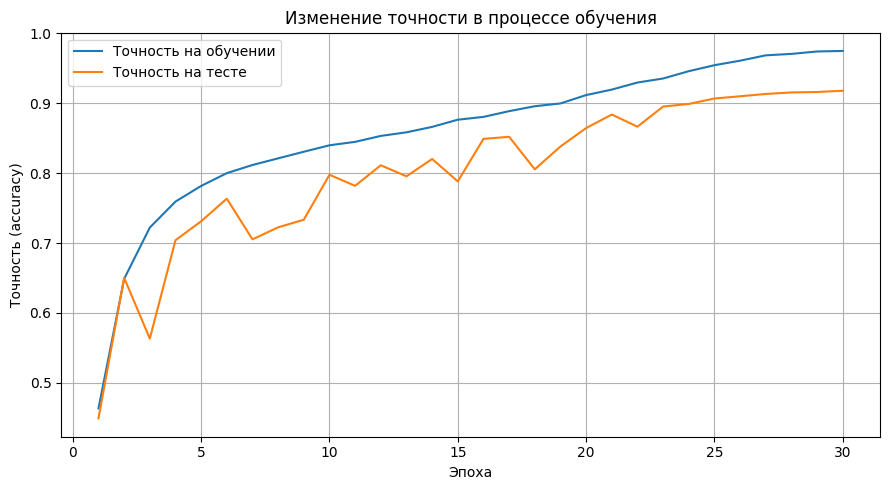

In [19]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS+1), history["train_acc"], label="Точность на обучении")
plt.plot(range(1, EPOCHS+1), history["test_acc"],  label="Точность на тесте")
plt.xlabel("Эпоха")
plt.ylabel("Точность (accuracy)")
plt.title("Изменение точности в процессе обучения")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()